# Phase 4 — Next-State Prediction Models (RQ3)

**Proposal sections:** 3.5 Predictive Models · 3.6 Temporal Validation & Leakage Control · 3.7 Model Evaluation

**Inputs:** `data/processed/customer_snapshot_panel.parquet` (for fold-wise state re-fitting), `data/processed/prediction_dataset.parquet` (notebook 03)
**Outputs:**
- `models/final_<model>_<config>.joblib` — six fitted classifiers
- `data/processed/phase4_test_predictions.parquet` — test predictions + class probabilities (input for the Phase 5 bootstrap)
- `outputs/tables/phase4_*.csv`, `outputs/figures/phase4_*.png`

**Design (identical for Config A and Config B — only the feature list differs)**

| Item | Choice |
|---|---|
| Rows | history-eligible customer × origin (present at t−2) |
| Config A | 8 current behavioural features + `Segment_t` |
| Config B | Config A + `Segment_t-1`, `Segment_t-2`, `StateDuration` |
| Classifiers | Multinomial Logistic Regression, Random Forest, XGBoost |
| Benchmarks | majority class; persistence (`Segment_t+1 = Segment_t`) |
| Tuning | expanding window: fold 1 = train S3 → validate S4; fold 2 = train S3–S4 → validate S5; states re-fitted on each fold's past snapshots |
| Selection metric | mean validation Macro-F1 over the two folds |
| Class imbalance | class weighting (none / balanced) is itself a tuned hyper-parameter |
| Final test | refit on all training origins S3–S5, evaluate **once** on S6–S7 |

In [1]:
import sys, warnings, pickle
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.inspection import permutation_importance

from config import (PROCESSED, INTERIM, TABLES, FIGURES, ROOT, TUNING_FOLDS, TARGET, N_STATES,
                    STATE_NAMES, STATE_COLORS, CONFIG_A, CONFIG_B, RANDOM_STATE)
import modeling as M

MODELS_DIR = ROOT / "models"; MODELS_DIR.mkdir(exist_ok=True)
TUNE_DIR = TABLES / "phase4_tuning_raw"
RECOMPUTE = False            # True = recompute tuning (≈ 3 minutes) and fold data
MODEL_NAMES = ["LogReg", "RandomForest", "XGBoost"]
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": "#9a9a92", "xtick.color": "#5c5c57", "ytick.color": "#5c5c57", "font.size": 10})
BLUES = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])
CFG_COLOR = {"A": "#2a78d6", "B": "#eb6834"}

## 1. Tuning folds (states re-fitted inside each fold)

In [2]:
FOLD_CACHE = INTERIM / "tuning_folds.pkl"
if FOLD_CACHE.exists() and not RECOMPUTE:
    folds = pickle.load(open(FOLD_CACHE, "rb"))
else:
    base = pd.read_parquet(PROCESSED / "customer_snapshot_panel.parquet")
    folds = {fd["fold"]: M.fold_data(base, fd)[:2] for fd in TUNING_FOLDS}
    pickle.dump(folds, open(FOLD_CACHE, "wb"))

fold_info = []
for fd in TUNING_FOLDS:
    tr, va = folds[fd["fold"]]
    yv = va[TARGET].astype(int).values
    bm = M.benchmark_predictions(tr, va)
    fold_info.append({"fold": fd["fold"], "train origins": "+".join(fd["train_origins"]), "validation origin": fd["val_origins"][0],
                      "states fitted on": f"S1–{M.SNAPSHOT_ORDER[M.SNAPSHOT_ORDER.index(fd['train_origins'][-1]) + 1]}",
                      "train rows": len(tr), "validation rows": len(va),
                      "persistence Macro-F1": M.f1_score(yv, bm["Persistence"], average="macro"),
                      "majority Macro-F1": M.f1_score(yv, bm["Majority class"], average="macro")})
fold_info = pd.DataFrame(fold_info)
fold_info

,fold,train origins,validation origin,states fitted on,train rows,validation rows,persistence Macro-F1,majority Macro-F1
0,1,S3,S4,S1–S4,2132,2946,0.6447,0.1452
1,2,S3+S4,S5,S1–S5,5078,3530,0.6450,0.1420


## 2. Hyper-parameter tuning

In [3]:
grid_size = {m: len(M.grid(m)) for m in MODEL_NAMES}
print("grid points per model:", grid_size, "| each evaluated on 2 folds × 2 configurations")
fold_pairs = {k: v for k, v in folds.items()}
tuning = pd.concat([M.tune(m, c, fold_pairs, TUNE_DIR, recompute=RECOMPUTE) for m in MODEL_NAMES for c in ["A", "B"]],
                   ignore_index=True)

summary = (tuning.groupby(["model", "config", "params"])
           .agg(val_macro_f1=("macro_f1", "mean"), fold1=("macro_f1", lambda s: s.iloc[0]),
                fold2=("macro_f1", lambda s: s.iloc[-1]), val_accuracy=("accuracy", "mean")).reset_index())
best = summary.loc[summary.groupby(["model", "config"])["val_macro_f1"].idxmax()].reset_index(drop=True)
best_params = {(r.model, r.config): M.best_params(tuning[(tuning.model == r.model) & (tuning.config == r.config)])[0]
               for r in best.itertuples()}
persist_val = fold_info["persistence Macro-F1"].mean()
best["Δ vs persistence (val)"] = best["val_macro_f1"] - persist_val
print(f"Persistence benchmark, mean validation Macro-F1: {persist_val:.4f}")
best

grid points per model: {'LogReg': 10, 'RandomForest': 24, 'XGBoost': 32} | each evaluated on 2 folds × 2 configurations
Persistence benchmark, mean validation Macro-F1: 0.6449


,model,config,params,val_macro_f1,fold1,fold2,val_accuracy,Δ vs persistence (val)
0,LogReg,A,"{'C': 0.01, 'class_weight': None}",0.6133,0.5855,0.6411,0.8026,-0.0316
1,LogReg,B,"{'C': 0.01, 'class_weight': None}",0.6102,0.5829,0.6375,0.7976,-0.0347
2,RandomForest,A,"{'max_depth': 8, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced'}",0.6339,0.6072,0.6606,0.8192,-0.0110
3,RandomForest,B,"{'max_depth': 16, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'class_weight': 'balanced'}",0.6340,0.6053,0.6628,0.8116,-0.0109
4,XGBoost,A,"{'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.1, 'min_child_weight': 5, 'class_weight': 'balanc...",0.6388,0.6180,0.6595,0.8047,-0.0061
5,XGBoost,B,"{'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.03, 'min_child_weight': 5, 'class_weight': 'balan...",0.6365,0.6079,0.6651,0.8100,-0.0084


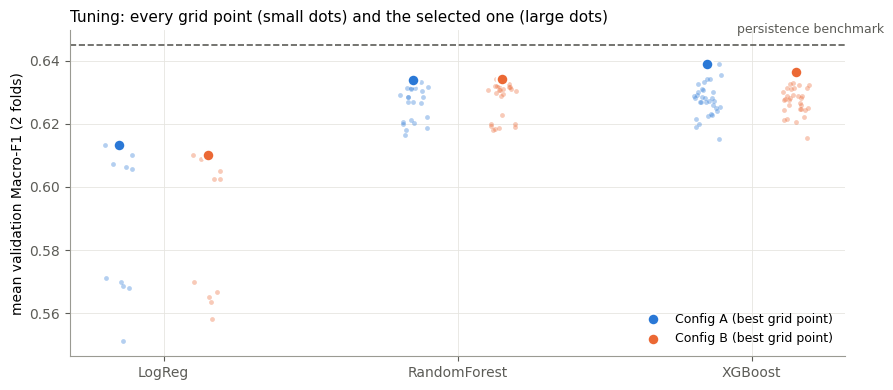

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for j, cfg in enumerate(["A", "B"]):
    for i, m in enumerate(MODEL_NAMES):
        vals = summary[(summary.model == m) & (summary.config == cfg)]["val_macro_f1"].values
        x = i + (j - 0.5) * 0.3
        ax.scatter(np.full(len(vals), x) + np.random.default_rng(i).uniform(-0.05, 0.05, len(vals)), vals,
                   s=12, color=CFG_COLOR[cfg], alpha=0.35, linewidths=0)
        ax.scatter([x], [vals.max()], s=70, color=CFG_COLOR[cfg], edgecolor="white", linewidth=1.5,
                   label=f"Config {cfg} (best grid point)" if i == 0 else None, zorder=3)
ax.axhline(persist_val, color="#5c5c57", linestyle="--", linewidth=1.2)
ax.text(2.45, persist_val + 0.004, "persistence benchmark", ha="right", fontsize=9, color="#5c5c57")
ax.set_xticks(range(3), MODEL_NAMES); ax.set_ylabel("mean validation Macro-F1 (2 folds)")
ax.set_title("Tuning: every grid point (small dots) and the selected one (large dots)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout(); fig.savefig(FIGURES / "phase4_tuning.png", dpi=150, bbox_inches="tight")

**Reading the tuning results.** On validation, the best grid points of all classifiers reach 0.61–0.64 mean Macro-F1 — all of them below the persistence benchmark (0.645), by 0.006 (XGBoost A) to 0.035 (Logistic Regression B). The tree models beat persistence on fold 2 (larger training set) but not on fold 1 (only 2,132 training rows from origin S3). The best Config A and Config B settings differ by at most 0.003 for every classifier. For the tree models the balanced class weights were selected; for Logistic Regression no weighting was better.

## 3. Final models: refit on S3–S5, evaluate once on S6–S7

In [5]:
ds = pd.read_parquet(PROCESSED / "prediction_dataset.parquet")
main = ds[ds["history_eligible"]]
train, test = main[main["split"] == "train"], main[main["split"] == "test"]
y_test = test[TARGET].astype(int).values
seg_test = test["Segment_t"].astype(int).values
print(f"train rows {len(train):,} (origins {sorted(train.origin.unique())}) | test rows {len(test):,} (origins {sorted(test.origin.unique())})")

preds = {}           # (model, config) -> (pred, proba)
for name, p in M.benchmark_predictions(train, test).items():
    preds[(name, "–")] = (p, None)
final_models = {}
for m in MODEL_NAMES:
    for cfg in ["A", "B"]:
        feats = M.CONFIGS[cfg]
        Xtr, ytr = M.to_xy(train, feats); Xte, _ = M.to_xy(test, feats)
        pipe = M.fit(m, M.make_model(m, feats, best_params[(m, cfg)]), Xtr, ytr)
        final_models[(m, cfg)] = pipe
        preds[(m, cfg)] = (pipe.predict(Xte), pipe.predict_proba(Xte))
        joblib.dump(pipe, MODELS_DIR / f"final_{m}_{cfg}.joblib")

results = pd.DataFrame([{"model": m, "config": c, **M.metrics(y_test, p, pr, seg_test)} for (m, c), (p, pr) in preds.items()])
results[["model", "config", "macro_f1", "weighted_f1", "accuracy", "balanced_accuracy", "macro_auc_ovr"]]

train rows 8,608 (origins ['S3', 'S4', 'S5']) | test rows 8,983 (origins ['S6', 'S7'])


,model,config,macro_f1,weighted_f1,accuracy,balanced_accuracy,macro_auc_ovr
0,Majority class,–,0.1302,0.1834,0.3521,0.2500,NaN
1,Persistence,–,0.6487,0.8064,0.8094,0.6459,NaN
2,LogReg,A,0.6357,0.8145,0.8338,0.6461,0.9041
3,LogReg,B,0.6386,0.8178,0.8370,0.6490,0.9054
4,RandomForest,A,0.6490,0.8228,0.8380,0.6544,0.9033
5,RandomForest,B,0.6485,0.8229,0.8389,0.6555,0.9000
6,XGBoost,A,0.6559,0.8130,0.8169,0.6521,0.8991
7,XGBoost,B,0.6570,0.8166,0.8238,0.6544,0.9010


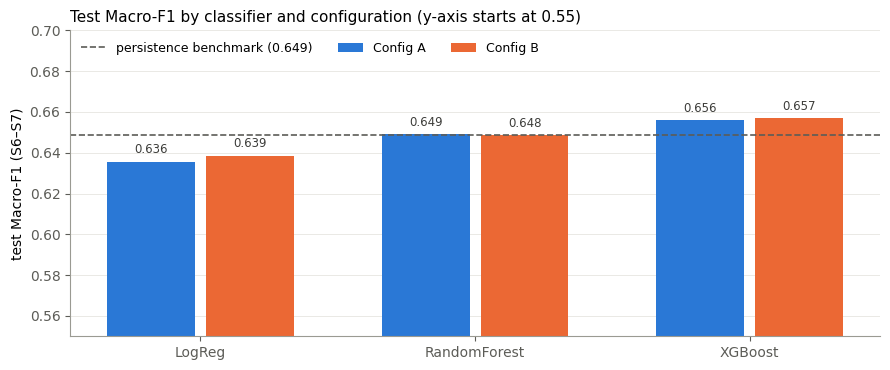

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
persist = results.loc[results.model == "Persistence", "macro_f1"].item()
w = 0.36
for j, cfg in enumerate(["A", "B"]):
    vals = [results[(results.model == m) & (results.config == cfg)]["macro_f1"].item() for m in MODEL_NAMES]
    xs = np.arange(3) + (j - 0.5) * w
    ax.bar(xs, vals, width=w - 0.04, color=CFG_COLOR[cfg], label=f"Config {cfg}")
    for x, v in zip(xs, vals):
        ax.text(x, v + 0.004, f"{v:.3f}", ha="center", fontsize=8.5, color="#3d3d3a")
ax.axhline(persist, color="#5c5c57", linestyle="--", linewidth=1.2, label=f"persistence benchmark ({persist:.3f})")
ax.set_xticks(range(3), MODEL_NAMES); ax.set_ylim(0.55, 0.70); ax.set_ylabel("test Macro-F1 (S6–S7)")
ax.set_title("Test Macro-F1 by classifier and configuration (y-axis starts at 0.55)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper left", ncol=3); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIGURES / "phase4_test_macro_f1.png", dpi=150, bbox_inches="tight")

## 4. Where do the models differ from persistence? Stayers vs. changers

In [7]:
results[["model", "config", "accuracy", "stayers_accuracy", "changers_n", "changers_accuracy", "changers_macro_f1"]]

,model,config,accuracy,stayers_accuracy,changers_n,changers_accuracy,changers_macro_f1
0,Majority class,–,0.3521,0.3440,1712,0.3867,0.1394
1,Persistence,–,0.8094,1.0000,1712,0.0000,0.0000
2,LogReg,A,0.8338,0.9900,1712,0.1706,0.1034
3,LogReg,B,0.8370,0.9869,1712,0.2004,0.1282
4,RandomForest,A,0.8380,0.9829,1712,0.2225,0.1733
5,RandomForest,B,0.8389,0.9809,1712,0.2360,0.1871
6,XGBoost,A,0.8169,0.9450,1712,0.2728,0.2312
7,XGBoost,B,0.8238,0.9560,1712,0.2623,0.2246


19 % of test observations change state (1,712 of 8,983). Persistence is right on every stayer and wrong on every changer by construction. The classifiers give up a little on stayers (accuracy 0.95–0.99) to catch 17–27 % of the changers. That trade is what the small Macro-F1 gains over persistence consist of.

## 5. Per-class performance

In [8]:
pc = []
for (m, c), (p, _) in preds.items():
    t = M.per_class(y_test, p); t.insert(0, "state", t.index.map(STATE_NAMES)); t.insert(0, "config", c); t.insert(0, "model", m)
    pc.append(t)
per_class = pd.concat(pc).reset_index(drop=True)
per_class.pivot_table(index=["model", "config"], columns="state", values="f1", sort=False)[[STATE_NAMES[i] for i in range(N_STATES)]]

state                  Dormant Low-Value  Lapsing Mid-Value  Recent Low-Frequency  Active High-Value
model          config                                                                               
Majority class –                  0.0000             0.5208                0.0000             0.0000
Persistence    –                  0.9168             0.7823                0.0865             0.8090
LogReg         A                  0.9182             0.8122                0.0000             0.8123
               B                  0.9173             0.8168                0.0000             0.8200
RandomForest   A                  0.9213             0.8202                0.0297             0.8247
               B                  0.9200             0.8204                0.0265             0.8268
XGBoost        A                  0.9031             0.8109                0.0970             0.8125
               B                  0.9082             0.8148                0.0893             0.8156

*Recent Low-Frequency* (≈ 4 % of test targets) is the hard class for every method: F1 is 0.00–0.03 for Logistic Regression and Random Forest, 0.09–0.10 for XGBoost and 0.09 for persistence. The other three states are predicted with F1 between 0.78 and 0.92. Because Macro-F1 averages the four classes equally, the near-zero F1 on this one class caps Macro-F1 at roughly 0.65–0.66 for all methods.

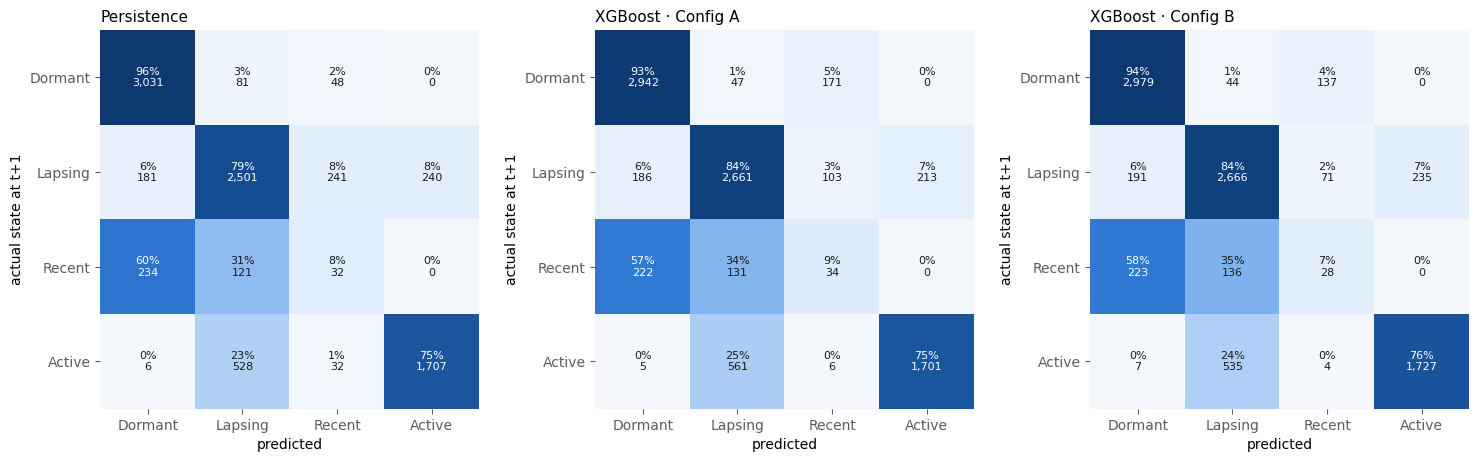

In [9]:
show = [("Persistence", "–"), ("XGBoost", "A"), ("XGBoost", "B")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
short = ["Dormant", "Lapsing", "Recent", "Active"]
for ax, key in zip(axes, show):
    cm = M.confusion_matrix(y_test, preds[key][0], labels=M.LABELS)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap=BLUES, vmin=0, vmax=1)
    for i in range(N_STATES):
        for j in range(N_STATES):
            ax.text(j, i, f"{cmn[i, j]:.0%}\n{cm[i, j]:,}", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.5 else "#1a1a19")
    ax.set_xticks(range(N_STATES), short); ax.set_yticks(range(N_STATES), short)
    ax.set_xlabel("predicted"); ax.set_ylabel("actual state at t+1"); ax.grid(False)
    ax.set_title(f"{key[0]}" + (f" · Config {key[1]}" if key[1] != "–" else ""), loc="left", fontsize=11)
    for s in ax.spines.values(): s.set_visible(False)
fig.tight_layout(); fig.savefig(FIGURES / "phase4_confusion_matrices.png", dpi=150, bbox_inches="tight")

## 6. Test performance per origin (S6→S7 vs. the shorter S7→S8)

In [10]:
by_origin = []
for o in sorted(test.origin.unique()):
    msk = (test.origin == o).values
    for (m, c), (p, _) in preds.items():
        by_origin.append({"origin": o, "model": m, "config": c,
                          "macro_f1": M.f1_score(y_test[msk], p[msk], average="macro", labels=M.LABELS, zero_division=0)})
by_origin = pd.DataFrame(by_origin).pivot_table(index=["model", "config"], columns="origin", values="macro_f1", sort=False)
by_origin

origin                    S6     S7
model          config              
Majority class –      0.1314 0.1291
Persistence    –      0.6539 0.6436
LogReg         A      0.6369 0.6341
               B      0.6409 0.6361
RandomForest   A      0.6503 0.6470
               B      0.6495 0.6468
XGBoost        A      0.6524 0.6587
               B      0.6510 0.6613

## 7. Historical-state gain Δ = Macro-F1(B) − Macro-F1(A) — point estimates

These are the quantities H1 and H2 are about. Their 95 % confidence intervals (paired customer-level bootstrap) are computed in Phase 5; here they are only reported as point estimates.

In [11]:
delta = pd.DataFrame([{"classifier": m,
                       "Macro-F1 A": results[(results.model == m) & (results.config == "A")]["macro_f1"].item(),
                       "Macro-F1 B": results[(results.model == m) & (results.config == "B")]["macro_f1"].item()}
                      for m in MODEL_NAMES])
delta["Δ (B − A)"] = delta["Macro-F1 B"] - delta["Macro-F1 A"]
delta

,classifier,Macro-F1 A,Macro-F1 B,Δ (B − A)
0,LogReg,0.6357,0.6386,0.0029
1,RandomForest,0.6490,0.6485,-0.0005
2,XGBoost,0.6559,0.6570,0.0011


## 8. Why does history add so little? Permutation importance (test, diagnostic only)

Permutation importance = drop in test Macro-F1 when one input column is shuffled (5 repeats). It is computed after model selection and does not influence any choice.

In [12]:
imp_rows = []
for m in ["RandomForest", "XGBoost"]:
    feats = CONFIG_B
    Xte, _ = M.to_xy(test, feats)
    r = permutation_importance(final_models[(m, "B")], Xte, y_test, scoring="f1_macro", n_repeats=5,
                               random_state=RANDOM_STATE, n_jobs=1)
    imp_rows.append(pd.Series(r.importances_mean, index=feats, name=m))
importance = pd.concat(imp_rows, axis=1).sort_values("XGBoost", ascending=False)
importance["group"] = ["history" if f in ["Segment_t-1", "Segment_t-2", "StateDuration"] else
                       ("current state" if f == "Segment_t" else "current behaviour") for f in importance.index]
importance

,RandomForest,XGBoost,group
Frequency,0.0103,0.1174,current behaviour
Monetary,0.0090,0.0853,current behaviour
Segment_t,0.0577,0.0198,current state
Recency,0.0024,0.0137,current behaviour
Tenure,0.0019,0.0066,current behaviour
ProductVariety,-0.0040,0.0051,current behaviour
Segment_t-1,0.0047,0.0025,history
Segment_t-2,0.0008,0.0015,history
RecentOrders,-0.0003,0.0009,current behaviour
StateDuration,0.0025,0.0006,history


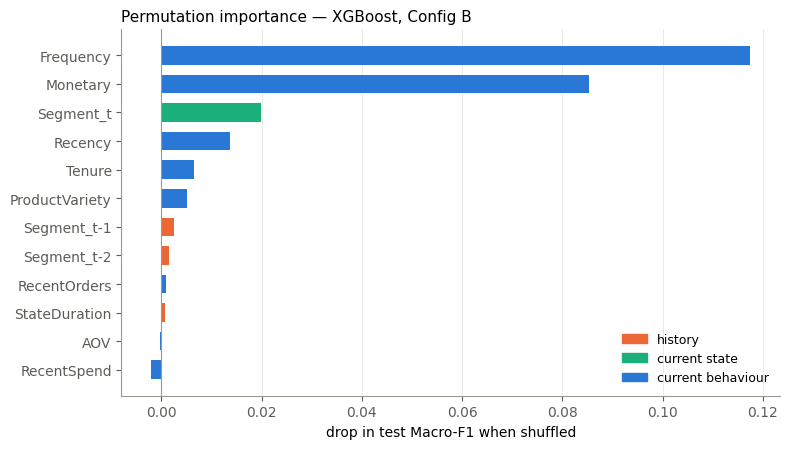

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.6))
imp = importance.sort_values("XGBoost")
gcol = {"history": "#eb6834", "current state": "#1baf7a", "current behaviour": "#2a78d6"}
ax.barh(imp.index, imp["XGBoost"], color=[gcol[g] for g in imp["group"]], height=0.65)
from matplotlib.patches import Patch
ax.axvline(0, color="#9a9a92", linewidth=0.8)
ax.set_xlabel("drop in test Macro-F1 when shuffled")
ax.legend(handles=[Patch(color=col, label=g) for g, col in gcol.items()], frameon=False, fontsize=9, loc="lower right")
ax.set_title("Permutation importance — XGBoost, Config B", loc="left", fontsize=11); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIGURES / "phase4_permutation_importance.png", dpi=150, bbox_inches="tight")

**Reading the importance.** XGBoost relies mainly on cumulative Frequency and Monetary, then on `Segment_t` and Recency; Random Forest relies mostly on `Segment_t`. The three history columns each reduce test Macro-F1 by less than 0.005 when shuffled. The current state and current RFM values already carry most of what the past states say. This is consistent with the near-zero Δ in section 7, even though the training-only Markov test in Phase 3 showed that past states matter *when only states are known*.

## 9. Save

In [14]:
out = test[["CustomerID", "origin", "target_snapshot", "Segment_t", TARGET]].reset_index(drop=True).copy()
for (m, c), (p, pr) in preds.items():
    tag = f"{m}_{c}".replace("–", "bench").replace(" ", "")
    out[f"pred_{tag}"] = p
    if pr is not None:
        for k in range(N_STATES):
            out[f"proba_{tag}_{k}"] = pr[:, k]
out.to_parquet(PROCESSED / "phase4_test_predictions.parquet", index=False)

fold_info.to_csv(TABLES / "phase4_tuning_folds.csv", index=False)
best.to_csv(TABLES / "phase4_best_params.csv", index=False)
results.to_csv(TABLES / "phase4_test_results.csv", index=False)
per_class.to_csv(TABLES / "phase4_per_class.csv", index=False)
by_origin.to_csv(TABLES / "phase4_test_by_origin.csv")
delta.to_csv(TABLES / "phase4_delta_point_estimates.csv", index=False)
importance.to_csv(TABLES / "phase4_permutation_importance.csv")
print(f"saved predictions for {len(out):,} test rows and {len(final_models)} models")

saved predictions for 8,983 test rows and 6 models


## Summary & hand-off to Phase 5

- See sections 3–8 for the numbers. Main points: the classifiers only slightly exceed the strong persistence benchmark on test Macro-F1; their value lies in catching part of the customers who change state; adding historical states (Config B) changes Macro-F1 by less than 0.005 for every classifier.
- Phase 5 tests H1 (Δ_c > 0) and H2 (Δ differs between classifiers) with a paired, customer-level bootstrap on `phase4_test_predictions.parquet`, and adds secondary-metric comparisons.